# Business analysis: Olist e-commerce

This notebook continues the original data-understanding notebook. First run `python -m src.olist_analytics` from the project root. It reads the existing raw files, creates the cleaned outputs, and validates Python against SQLite.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', palette='deep')
root = Path('..') if Path('../data/processed/order_summary.csv').exists() else Path('.')
summary_path = root / 'data/processed/order_summary.csv'
items_path = root / 'data/processed/order_items_enriched.csv'
if not summary_path.exists():
    raise FileNotFoundError('Run `python -m src.olist_analytics` from the project root first.')
orders = pd.read_csv(summary_path, parse_dates=['order_purchase_timestamp', 'order_delivered_customer_date', 'order_estimated_delivery_date'])
items = pd.read_csv(items_path, parse_dates=['order_purchase_timestamp'])
delivered = orders.loc[orders['order_status'].eq('delivered')].copy()
print(f'Orders: {len(orders):,}; delivered: {len(delivered):,}')

Orders: 99,441; delivered: 96,478


## 1. Payment revenue over time

Payment value is aggregated to order level before analysis. This avoids double counting when an order contains several items or payment components.

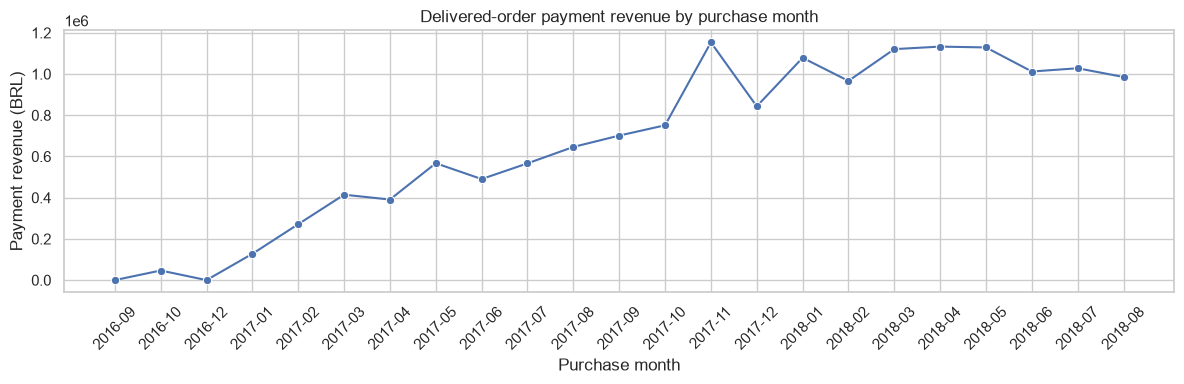

,purchase_month,payment_revenue,delivered_orders
13,2017-11,1153528.05,7289
18,2018-04,1132933.95,6798
19,2018-05,1128836.69,6749
17,2018-03,1120678.00,7003
15,2018-01,1078606.86,7069


In [2]:
monthly = delivered.groupby('purchase_month', as_index=False).agg(payment_revenue=('payment_value', 'sum'), delivered_orders=('order_id', 'nunique'))
fig, ax = plt.subplots(figsize=(12, 4))
sns.lineplot(data=monthly, x='purchase_month', y='payment_revenue', marker='o', ax=ax)
ax.set(title='Delivered-order payment revenue by purchase month', xlabel='Purchase month', ylabel='Payment revenue (BRL)')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()
monthly.sort_values('payment_revenue', ascending=False).head()

**Verified observation:** November 2017 is the highest-payment-revenue month in this dataset (BRL 1,153,528.05 across 7,289 delivered orders). This is a historical pattern, not a prediction.

## 2. State and category performance

State is based on the customer address. Category GMV is item price only, so it excludes freight and should not be called payment revenue.

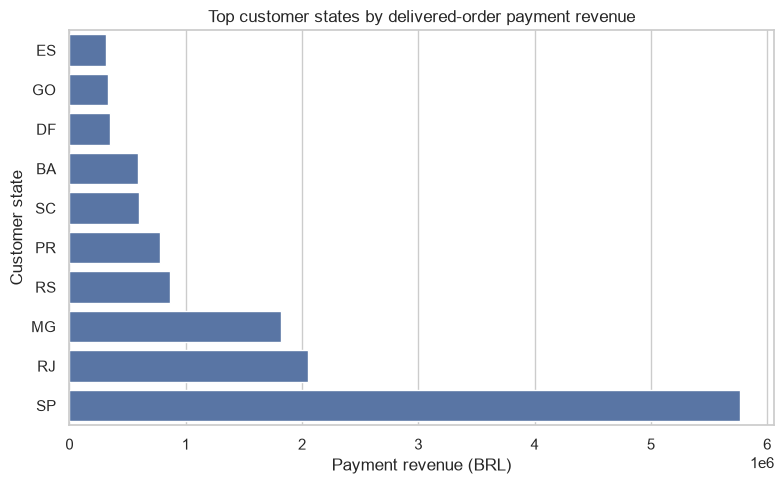

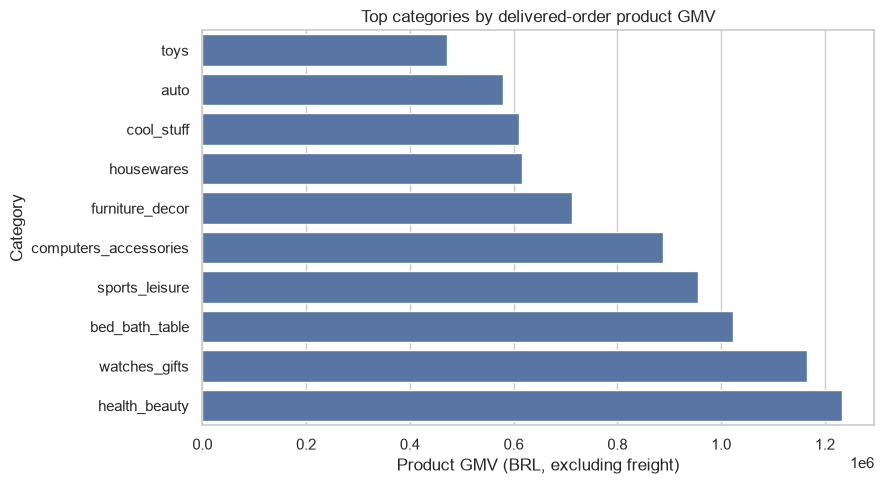

,category,product_gmv,units
43,health_beauty,1233131.72,9465
73,watches_gifts,1166176.98,5859
7,bed_bath_table,1023434.76,10953
67,sports_leisure,954852.55,8431
15,computers_accessories,888724.61,7644


In [3]:
state_revenue = (delivered.groupby('customer_state', as_index=False)['payment_value'].sum()
                 .nlargest(10, 'payment_value').sort_values('payment_value'))
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=state_revenue, x='payment_value', y='customer_state', ax=ax)
ax.set(title='Top customer states by delivered-order payment revenue', xlabel='Payment revenue (BRL)', ylabel='Customer state')
plt.tight_layout()
plt.show()

category = (items.loc[items['order_status'].eq('delivered')]
            .assign(category=lambda x: x['product_category_name_english'].fillna(x['product_category_name']).fillna('unclassified'))
            .groupby('category', as_index=False).agg(product_gmv=('price', 'sum'), units=('order_item_id', 'count'))
            .nlargest(10, 'product_gmv').sort_values('product_gmv'))
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=category, x='product_gmv', y='category', ax=ax)
ax.set(title='Top categories by delivered-order product GMV', xlabel='Product GMV (BRL, excluding freight)', ylabel='Category')
plt.tight_layout()
plt.show()
category.sort_values('product_gmv', ascending=False).head()

**Verified observations:** SP has the highest delivered-order payment revenue (BRL 5,770,266.19). `health_beauty` has the highest product GMV (BRL 1,233,131.72 across 9,465 items).

## 3. Delivery performance and customer reviews

A positive delay means delivery occurred after the estimated delivery date. Missing dates are excluded from this comparison.

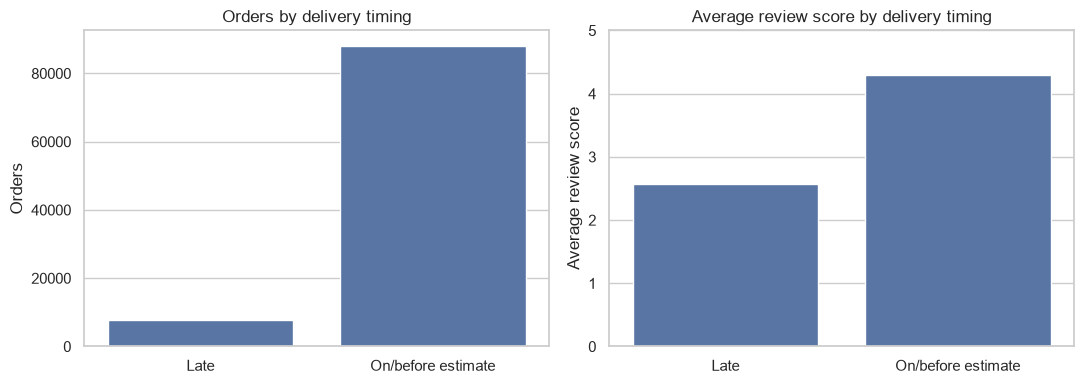

,delivery_timing,orders,average_review
0,Late,7661,2.566506
1,On/before estimate,88163,4.294292


In [4]:
delivery = delivered.dropna(subset=['delivery_delay_days', 'review_score']).copy()
delivery['delivery_timing'] = delivery['delivery_delay_days'].gt(0).map({True: 'Late', False: 'On/before estimate'})
timing = delivery.groupby('delivery_timing', as_index=False).agg(orders=('order_id', 'count'), average_review=('review_score', 'mean'))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(data=timing, x='delivery_timing', y='orders', ax=axes[0])
axes[0].set(title='Orders by delivery timing', xlabel='', ylabel='Orders')
sns.barplot(data=timing, x='delivery_timing', y='average_review', ax=axes[1])
axes[1].set(title='Average review score by delivery timing', xlabel='', ylabel='Average review score')
axes[1].set_ylim(0, 5)
plt.tight_layout()
plt.show()
timing

**Verified observation:** late delivered orders average a 2.57 review score, compared with 4.29 for orders delivered on or before estimate. This is an association; other factors may also affect reviews.

## Next step
Use the same processed files in Power BI and reconcile KPI cards with the SQLite values listed in `docs/power-bi-guide.md`.